In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display

##### Note: Every price path SOlution in here will use the exact discretization instead of euler linear approximation
## Geometric Brownian Motion:

$dS_t​=μS_t​dt+σS_t​dW_t​$

consists of a trend and random movement

I went over this specific topic in another video already, so i dont want to fucking repeat everything.

The solution for GBM:

### $S_{t+Δt}​=S_t ​exp[(μ−\frac{σ^2​}{2})Δt+σΔtZ]$

In [2]:
class GBM:
    def __init__(self, drift, volatility, dt, initial_asset_price):
        self.drift = drift
        self.volatility = volatility
        self.dt = dt
        self.asset_prices = [initial_asset_price]
        self.current_asset_price = initial_asset_price

    def time_step(self):
        dW = np.random.normal(0, math.sqrt(self.dt))
        dS = self.drift * self.dt * self.current_asset_price + self.volatility * self.current_asset_price * dW
        
        self.asset_prices.append(self.current_asset_price + dS)
        self.current_asset_price = self.current_asset_price + dS
    
    def time_step_exact(self):
        z = np.random.normal()

        self.current_asset_price *= math.exp(
            (self.drift - 0.5 * self.volatility**2) * self.dt
            + self.volatility * math.sqrt(self.dt) * z
        )

        self.asset_prices.append(self.current_asset_price)


In [4]:

def plot_simple_gbm(drift=.2,volatility=.3,initial_asset_price=300):
    plt.figure(figsize=(10,5))
    for i in range(10):
        process= GBM(drift=drift,volatility=volatility,dt=1/365,initial_asset_price=initial_asset_price)
    
    
    
        tte = 1
        while(tte - process.dt) > 0:
            process.time_step()
            tte = tte - process.dt
        plt.plot(process.asset_prices)
        
    plt.xlabel("Time Steps")
    plt.ylabel("Asset Price")
    plt.title("SImple GBM Process")

widgets.interact(
    plot_simple_gbm,
    drift=(-2,2,0.01),
    volatility=(0.0001, 2,0.001),
    initial_asset_price=(0.01,10000,0.01)
)

interactive(children=(FloatSlider(value=0.2, description='drift', max=2.0, min=-2.0, step=0.01), FloatSlider(v…

<function __main__.plot_simple_gbm(drift=0.2, volatility=0.3, initial_asset_price=300)>

# Price of a Call
 - We CAN use the closed-form formula, but unless you want to deal with Fourier Transforms and calc 3 shit, go ahead.
 - Instead i use Monte Carlo SImulation. For me this is just much simpler. Also, it works for exotics (asian, lookback, barrier options...)

Monte Carlo:

$C=e^{−rT}\frac{1}{N}​\sum^{N}_{i=1}​max(S_{T}^{(i)}​−K,0)​$ 


Or use whatever weird payoff function you need for pricing kuwaiti premium grade uranium-enriched oil exotic options

In [5]:


class MonteCarloSim:
    def __init__(self, process, call_strike, n_options, rfr, tte, barrier=100, exotics=False):
        self.stochastic_processes = []
        n_steps = round(tte / process.dt)  # valid when T is a whole number of time steps


        
        for _ in range(n_options):
            path = copy.deepcopy(process)
            ttei = tte
            while ttei > 0:
                path.time_step()
                ttei -= process.dt
            self.stochastic_processes.append(path)

        
        self.final_prices = []
        self.all = []
        self.payoffs = []
        self.payoffs_hist = []
        discount = math.exp(-rfr * tte)
        running_sum = 0.0
        
        for i, stochastic_process in enumerate(self.stochastic_processes, start=1):
            final_price = stochastic_process.asset_prices[-1]
            self.all.append(stochastic_process.asset_prices)
            self.final_prices.append(final_price)
        
            payoff = max(final_price - call_strike, 0)
            self.payoffs.append(payoff)
        
            running_sum += payoff
            self.payoffs_hist.append(running_sum / i * discount)

        
        self.price = np.mean(self.payoffs) * discount



### Test Monte Carlo with simple GBM

In [6]:
import yfinance as yf
asset = yf.Ticker("SPY")
SPOT_PRICE = asset.fast_info.last_price
expirations = asset.options
day = 5
print(expirations[day])
calls = asset.option_chain(expirations[day]).calls
itm = calls[calls['inTheMoney'] ==True]
itm.sample(5)

$SPY: possibly delisted; no price data found  (period=1y)
$SPY: possibly delisted; no price data found  (period=5d)


KeyError: 'currentTradingPeriod'

In [186]:
c = itm.sample().iloc[0]
c

contractSymbol              SPY261022C00755000
lastTradeDate        2026-10-14 15:47:22+00:00
strike                                   755.0
lastPrice                                17.74
bid                                      15.96
ask                                      16.13
change                                     0.0
percentChange                              0.0
volume                                     NaN
openInterest                               2.0
impliedVolatility                     0.138558
inTheMoney                                True
contractSize                           REGULAR
currency                                   USD
Name: 9, dtype: object

In [187]:
test = MonteCarloSim(process=GBM(drift=0.08, volatility=c['impliedVolatility'], dt=1/365, initial_asset_price=SPOT_PRICE),
                     call_strike=c['strike'], n_options=1000,  rfr=0.04, tte=7/365, barrier=800)

In [188]:
test.price

18.085073885756323

# Merton Jump Diffusion

SOmetimes prices jump quickly, so Robert Merton added another term to basic GBM:

$(J-1)dN_t $

 - When a jump happens, J controls the size of the jump
 - To determine when a jump arrives (jump frequency), use Posison Process:

$N_t $ ~ $ Poisson(\lambda t)$


where $\lambda$ = Jump frequency

 - How much does the stock move during the jump? this is also random

$J = e^Y$


where $Y = N(\mu_j,\sigma^{2}_J)$


### But Adding jumps changes the expected return, so Merton includes a compensation term to keep $\mu\$ as the desired expected return.

$\kappa = E[J-1]$ (returns adjusted from avergae size of the jumps)


So the drift $\mu$ becomes $\mu - \lambda \kappa$

SO in total it should look like this: 

## $\frac{dS_t}{S_{t^-}} = (\mu-\lambda\kappa) dt + \sigma dW_t + (J-1)dN_t$

The final solution for the time step function should look like this: (Once again i dont want to fucking solve everything out here, and using euler approximation is inaccurate so u can go torture yourselves and read the full research papers)

### $St+Δt​=S_t​exp[(μ−λκ−1/2​σ^2)Δt+σΔW]∏^{Nt}_{i=1}​J_i​$

In [7]:

class MertonJumpProcess:
    def __init__(self, initial_asset_price, mu, sigma, Lambda, mu_j, sigma_j, dt):
        self.current_asset_price = initial_asset_price
        self.mu = mu
        self.sigma = sigma
        self.lambda_ = Lambda
        self.mu_J = mu_j
        self.sigma_J = sigma_j
        self.dt = dt
        # compensator: E[J - 1], constant
        self.k = np.exp(mu_j + 0.5 * sigma_j**2) - 1
        self.asset_prices = [initial_asset_price]

    def time_step(self):
        """Euler scheme (approximate)."""
        S = self.current_asset_price
        Nt = np.random.poisson(self.lambda_ * self.dt)
        dW = np.random.normal(0, np.sqrt(self.dt))

        # sum of (J_i - 1) over the Nt jumps in this step
        jump_term = np.sum(np.exp(np.random.normal(self.mu_J, self.sigma_J, Nt)) - 1)

        dS = S * ((self.mu - self.lambda_ * self.k) * self.dt
                  + self.sigma * dW
                  + jump_term)

        self.current_asset_price = S + dS
        self.asset_prices.append(self.current_asset_price)

    def time_step_exact(self):
        """Exact solution of the SDE over one step."""
        Nt = np.random.poisson(self.lambda_ * self.dt)
        dW = np.random.normal(0, np.sqrt(self.dt))

        # product of J_i = exp(sum of Y_i); sum of Nt normals is N(Nt*mu_J, Nt*sigma_J^2)
        jump = np.exp(np.sum(np.random.normal(self.mu_J, self.sigma_J, Nt)))

        self.current_asset_price *= np.exp(
            (self.mu - self.lambda_ * self.k - 0.5 * self.sigma**2) * self.dt
            + self.sigma * dW
        ) * jump
        self.asset_prices.append(self.current_asset_price)

In [8]:

def plot_merton(mu = .2, sigma = .3, Lambda = .2, mu_j=.2, sigma_j = .2):
    plt.figure(figsize=(10,5))
    for i in range(20):
        process= MertonJumpProcess(initial_asset_price = 100, mu = mu, sigma = sigma, Lambda = Lambda, mu_j=mu_j, sigma_j = sigma_j , dt=1/365)
    
        tte = 1
        while(tte - process.dt) > 0:
            process.time_step()
            tte = tte - process.dt
        plt.plot(process.asset_prices)

    plt.xlabel("Time Steps")
    plt.ylabel("Asset Price")
    plt.title("Merton Jump Diffusion")
    

widgets.interact(
    plot_merton,
    initial_asset_price=(50, 200, 10),
    mu=(-0.2, 0.3, 0.01),
    sigma=(0.05, 1.0, 0.05),
    Lambda=(0, 10, 0.5),
    mu_J=(-0.3, 0.3, 0.01),
    sigma_J=(0.01, 0.5, 0.01),
)


interactive(children=(FloatSlider(value=0.2, description='mu', max=0.3, min=-0.2, step=0.01), FloatSlider(valu…

<function __main__.plot_merton(mu=0.2, sigma=0.3, Lambda=0.2, mu_j=0.2, sigma_j=0.2)>

### Heston Model
 - Reminder: Original BS equation:

$dS_t​=μS_t​dt+σS_t​dW_t​$

 - One of the bad things about BS is that it assumes constant volatility throughout the entire stochastic process. This is of course not true in real markets
 - Instead of fixed $\sigma$, now $\sigma = \sqrt{\nu_t}$ where $\nu_t$ is the current variance
 - He proposed that a stock price moves like this instead:

## $ dS_{t}=\mu S_{t}\,dt+{\sqrt {\nu _{t}}}S_{t}\,dW_{t}^{S}$

and the volatility

## $d\nu _{t}=\kappa (\theta -\nu _{t})\,dt+\xi {\sqrt {\nu _{t}}}\,dW_{t}^{\nu }$


Where
 - $ \nu _{0}$, the initial variance.
 - $ \theta $, the long variance, or long-run average variance of the price; as t tends to infinity, the expected value of νt tends to θ.
 - $\rho $, the correlation of the two Wiener processes. E.g. when $\rho < 0$, a falling stock leads to increased volatility.
 - $\kappa $, the rate at which νt reverts to θ.
 - #### $ \xi $, the volatility of the volatility, or 'vol of vol', which determines the variance of νt.


#### This means that the stock price's randomness is controlled by something random as well. Price movement = mean reversion + randomness.
 

In [9]:

class HestonProcess:
    """
    Heston stochastic volatility model:

        dS_t = mu * S_t * dt + sqrt(v_t) * S_t * dW_t^S

        dv_t = kappa * (theta - v_t) * dt
               + xi * sqrt(v_t) * dW_t^v

    with:
        corr(dW_t^S, dW_t^v) = rho
    """

    def __init__(
        self,
        initial_asset_price,
        initial_variance,
        mu,
        kappa,
        theta,
        xi,
        rho,
        dt,
    ):
        self.current_asset_price = initial_asset_price
        self.current_variance = initial_variance

        self.mu = mu
        self.kappa = kappa
        self.theta = theta
        self.xi = xi
        self.rho = rho
        self.dt = dt

        # Stores the simulated asset-price path
        self.asset_prices = [initial_asset_price]
        self.variances = [initial_variance]

    def time_step(self):
        S = self.current_asset_price
        # Two independent standard normal random variables
        z1 = np.random.normal()
        z2 = np.random.normal()

        # Correlated Brownian increments (corr=rho)
        dW_asset = np.sqrt(self.dt) * z1
        dW_variance = np.sqrt(self.dt) * (
            self.rho * z1 + np.sqrt(1 - self.rho**2) * z2
        )

        # Update variance using Euler
        new_variance = (
            self.current_variance
            + self.kappa * (self.theta - self.current_variance) * self.dt
            + self.xi * np.sqrt(self.current_variance) * dW_variance
        )

        # Full truncation: variance cannot be negative
        new_variance = max(new_variance, 0.0)

        dS = self.mu * S * self.dt + np.sqrt(new_variance) * self.current_asset_price * dW_asset
        new_price = S + dS

        # Update state
        self.current_variance = new_variance
        self.current_asset_price = new_price

        # Store the new price
        self.asset_prices.append(new_price)
        self.variances.append(new_variance)

        

    def time_step_exact(self):
        S = self.current_asset_price
        v = self.current_variance
        v_plus = max(v, 0.0)  # full truncation: used in all coefficients

        z1 = np.random.normal()
        z2 = np.random.normal()
        sqrt_dt = np.sqrt(self.dt)

        dW_asset = sqrt_dt * z1
        dW_variance = sqrt_dt * (self.rho * z1 + np.sqrt(1 - self.rho**2) * z2)

        # Price: log step using the variance at the START of the interval
        new_price = S * np.exp((self.mu - 0.5 * v_plus) * self.dt
                               + np.sqrt(v_plus) * dW_asset)

        # Variance: Euler with full truncation (raw v can dip below 0)
        new_variance = (v
                        + self.kappa * (self.theta - v_plus) * self.dt
                        + self.xi * np.sqrt(v_plus) * dW_variance)

        self.current_asset_price = new_price
        self.current_variance = new_variance
        self.asset_prices.append(new_price)
        self.variances.append(new_variance)



In [10]:
model = HestonProcess(
    initial_asset_price=100.0,
    initial_variance=0.04,
    mu=0.05,
    kappa=2.0,
    theta=0.04,
    xi=0.3,
    rho=-0.7,
    dt=1 / 2000,
)

tte = 1
while(tte - model.dt) > 0:
    model.time_step()
    tte -= model.dt

In [11]:



def plot_heston(mu=0.05, kappa=2.0, theta=0.04, xi=0.3, rho=-0.7):
    model = HestonProcess(
        initial_asset_price=100,
        initial_variance=0.04,
        mu=mu,
        kappa=kappa,
        theta=theta,
        xi=xi,
        rho=rho,
        dt = 1/1000
    )
    tte = 1
    while(tte - model.dt) > 0:
        model.time_step()
        tte -= model.dt

    fig = plt.figure(figsize=(12,8))
    gs = fig.add_gridspec(2,2)
    ax1 = fig.add_subplot(gs[0, 0])   # top left
    ax2 = fig.add_subplot(gs[0, 1])   # top right
    ax3 = fig.add_subplot(gs[1, :])   # bottom, spans both columns
    
    ax1.plot(model.asset_prices)
    ax1.set_ylabel("Stock Price")
    ax1.set_title("Asset Price")
    
    ax2.plot(model.variances, color="red")
    ax2.set_ylabel("Variance")
    ax2.set_title("Asset Variance")
    ax2.axhline(model.theta, color="green", linestyle="--", label="long-run variance (theta)")
    ax2.legend()
    
    ax3.plot(model.asset_prices, color="blue", label="Stock Price")
    ax3.set_xlabel("Time")
    ax3.set_ylabel("Stock Price", color="blue")
    ax3.tick_params(axis="y", labelcolor="blue")
    
    ax3t = ax3.twinx()
    ax3t.plot(model.variances, color="red", label="Variance", linestyle="--", linewidth="1")
    ax3t.set_ylabel("Variance", color="red")
    ax3t.tick_params(axis="y", labelcolor="red")
    ax3t.axhline(model.theta, linestyle="--", color="green", label="long-run variance (theta)")
    
    plt.tight_layout()
    
    plt.title("Heston Process")
    plt.show()


widgets.interact(
    plot_heston,
    mu=(-2, 2, 0.01),
    kappa=(0.1, 10.0, 0.1),
    theta=(0.001, 0.2, 0.001),
    xi=(-1.0, 1.0, 0.01),
    rho=(-1.0, 1.0, 0.05),
    
);

interactive(children=(FloatSlider(value=0.05, description='mu', max=2.0, min=-2.0, step=0.01), FloatSlider(val…

# Combining Heston Process and Merton Jump Diffustion:

### $\frac{dS_t}{S_{t^-}} = (\mu-\lambda\kappa_{J}) dt + (J-1)dN_t +{\sqrt {\nu _{t}}}\,dW_{t}$

with

$d\nu =\kappa_\nu (\theta -\nu _{t})\,dt+\xi {\sqrt {\nu _{t}}}\,dW_{t}^{\nu }$

Solving this yields:

### $S_{t+Δt}​=S_t​exp[(r−λ_{κ_J}​−\frac{1}{2}​V_t^+​)Δt+\sqrt{V_t^+}​​ΔW_t^S​]∏_{i=1}^{N_t}​​J_i​​$

Where

$N_t​∼Poisson(λΔt)$

and

$J_i​=e^{Y_i}​,Y_i​∼N(μ_J​,σ_J^2​).$

Jump compensation is:

$κ_J​=E[J−1]=exp(μ_J​+\frac{1}{2}​σ_J^2)​−1​$

$$$$

In [12]:
class HestonMertonGBM:
    def __init__(self, initial_asset_price, mu, Lambda , mu_j, sigma_j, 
                 initial_variance, kappa_v, theta, xi, rho, dt):
        self.current_asset_price = initial_asset_price
        self.current_variance = initial_variance

        self.Lambda = Lambda
        self.mu_J = mu_j
        self.sigma_J = sigma_j
        # compensator: E[J - 1], constant
        self.kappa_J = np.exp(mu_j + 0.5 * sigma_j**2) - 1
        
        self.mu = mu
        self.kappa_V = kappa_v
        self.theta = theta
        self.xi = xi
        self.rho = rho
        self.dt = dt

        self.asset_prices = [initial_asset_price]
        self.variances = [initial_variance]

    def time_step(self):
        sqrt_dt = np.sqrt(self.dt)
        V = max(self.current_variance, 0.0)

        z1 = np.random.normal()
        z2 = np.random.normal()
        dW_S = sqrt_dt * z1
        dW_V = sqrt_dt * (self.rho * z1 + np.sqrt(1 - self.rho**2) * z2)

        # Variance: Euler with truncation
        new_V = max(V + self.kappa_V * (self.theta - V) * self.dt
                    + self.xi * np.sqrt(V) * dW_V, 0.0)

        # Jumps: product of J_i = exp(sum of Y_i)
        N = np.random.poisson(self.Lambda * self.dt)
        jump = np.exp(np.sum(np.random.normal(self.mu_J, self.sigma_J, N)))

        # Price: exact given V (start of step)
        new_S = self.current_asset_price * np.exp(
            (self.mu - self.Lambda * self.kappa_J - 0.5 * V) * self.dt
            + np.sqrt(V) * dW_S
        ) * jump

        self.current_asset_price = new_S
        self.current_variance = new_V
        self.asset_prices.append(new_S)
        self.variances.append(new_V)

    def time_step_exact(self):
        # Brownian motions
        z1 = np.random.normal()
        z2 = np.random.normal()
        
        dW_S = np.sqrt(self.dt) * z1
        dW_V = np.sqrt(self.dt) * (
            self.rho * z1 + np.sqrt(1 - self.rho**2) * z2
        )
        
        V = max(self.current_variance, 0)
        
        # Heston variance
        new_V = (
            V
            + self.kappa_V * (self.theta - V) * self.dt
            + self.xi * np.sqrt(V) * dW_V
        )
        
        new_V = max(new_V, 0)
        
        # Merton jumps
        N = np.random.poisson(self.Lambda * self.dt)
        
        jump = 1
        
        for _ in range(N):
            Y = np.random.normal(self.mu_J, self.sigma_J)
            J = np.exp(Y)
            jump *= J
        
        # Heston + Merton asset price
        new_S = self.current_asset_price * np.exp(
            (self.mu - self.Lambda * self.kappa_J - 0.5 * V) * self.dt
            + np.sqrt(V) * dW_S
        ) * jump

        self.current_asset_price = new_S
        self.current_variance = new_V

        self.asset_prices.append(new_S)
        self.variances.append(new_V)

In [13]:



def plot_hestonmerton(mu=0.05, Lambda = .2, mu_j=.2, sigma_j = .2,  kappa_v=2.0, theta=0.04, xi=0.3, rho=-0.7):
    model = HestonMertonGBM(
        initial_asset_price=100,
        Lambda = Lambda,
        mu_j = mu_j,
        sigma_j = sigma_j,
        initial_variance=0.04,
        mu=mu,
        kappa_v=kappa_v,
        theta=theta,
        xi=xi,
        rho=rho,
        dt = 1/365
    )
    tte = 1
    while(tte - model.dt) > 0:
        model.time_step()
        tte -= model.dt

    fig = plt.figure(figsize=(12,8))
    gs = fig.add_gridspec(2,2)
    ax1 = fig.add_subplot(gs[0, 0])   # top left
    ax2 = fig.add_subplot(gs[0, 1])   # top right
    ax3 = fig.add_subplot(gs[1, :])   # bottom, spans both columns
    
    ax1.plot(model.asset_prices)
    ax1.set_ylabel("Stock Price")
    ax1.set_title("Asset Price")
    
    ax2.plot(model.variances, color="red")
    ax2.set_ylabel("Variance")
    ax2.set_title("Asset Variance")
    ax2.axhline(model.theta, color="green", linestyle="--", label="long-run variance (theta)")
    ax2.legend()
    
    ax3.plot(model.asset_prices, color="blue", label="Stock Price")
    ax3.set_xlabel("Time")
    ax3.set_ylabel("Stock Price", color="blue")
    ax3.tick_params(axis="y", labelcolor="blue")
    
    ax3t = ax3.twinx()
    ax3t.plot(model.variances, color="red", label="Variance", linestyle="--", linewidth="1")
    ax3t.set_ylabel("Variance", color="red")
    ax3t.tick_params(axis="y", labelcolor="red")
    ax3t.axhline(model.theta, linestyle="--", color="green", label="long-run variance (theta)")
    
    #plt.tight_layout()
    
    plt.title("Heston Merton Process")
    plt.show()


widgets.interact(
    plot_hestonmerton,

    mu=(-0.2, 0.3, 0.01),

    kappa=(0.1, 10.0, 0.1),
    theta=(0.005, 0.15, 0.005),
    xi=(0.05, 1.0, 0.05),
    rho=(-1.0, 1.0, 0.05),

    Lambda=(0.0, 10.0, 0.5),
    mu_J=(-0.3, 0.3, 0.01),
    sigma_J=(0.01, 0.5, 0.01),
);

interactive(children=(FloatSlider(value=0.05, description='mu', max=0.3, min=-0.2, step=0.01), FloatSlider(val…

In [15]:



def plot_hestonmerton_multiple(mu=0.05, Lambda = .2, mu_j=.2, sigma_j = .2,  kappa_v=2.0, theta=0.04, xi=0.3, rho=-0.7):
    plt.figure(figsize=(15,5))
    for i in range(20):
        model = HestonMertonGBM(
            initial_asset_price=100,
            Lambda = Lambda,
            mu_j = mu_j,
            sigma_j = sigma_j,
            initial_variance=0.04,
            mu=mu,
            kappa_v=kappa_v,
            theta=theta,
            xi=xi,
            rho=rho,
            dt = 1/365
        )
        tte = 1
        while(tte - model.dt) > 0:
            model.time_step()
            tte -= model.dt

        
        plt.plot(model.asset_prices)

    
    plt.title("Heston Merton Process")
    plt.xlabel("Time Steps")
    plt.ylabel("Asset Price")
    plt.show()


widgets.interact(
    plot_hestonmerton_multiple,

    mu=(-0.2, 0.3, 0.01),

    kappa=(0.1, 10.0, 0.1),
    theta=(0.005, 0.15, 0.005),
    xi=(0.05, 1.0, 0.05),
    rho=(-1.0, 1.0, 0.05),

    Lambda=(0.0, 2.0, 0.01),
    mu_J=(-0.3, 0.3, 0.01),
    sigma_J=(0.01, 0.5, 0.01),
);

interactive(children=(FloatSlider(value=0.05, description='mu', max=0.3, min=-0.2, step=0.01), FloatSlider(val…

# Trying out this new model

In [190]:
c = itm.sample().iloc[0]
c

contractSymbol              SPY261022C00747000
lastTradeDate        2026-10-15 16:26:10+00:00
strike                                   747.0
lastPrice                                23.49
bid                                      22.69
ask                                      24.64
change                                0.709999
percentChange                         3.231675
volume                                    20.0
openInterest                               5.0
impliedVolatility                     0.205025
inTheMoney                                True
contractSize                           REGULAR
currency                                   USD
Name: 6, dtype: object

In [26]:

def mc_price_heston_merton(spot, strike ,init_variance, T):
    process=HestonMertonGBM(initial_asset_price=spot, mu=0.04, Lambda = .2, mu_j=.2, sigma_j = .2, 
                                           kappa_v=2.0, theta=0.04, xi=0.3, rho=-0.7,
                                           initial_variance=init_variance, dt = 1/365)
    test = MonteCarloSim(process,call_strike=strike, n_options=1000,  rfr=0.04, tte=T, barrier=400)
    return test
#mc = mc_price_heston_merton(SPOT_PRICE,c['strike'], c['impliedVolatility'], 7/365)
mc = mc_price_heston_merton(700,700, 0.05, 7/365)
mc.price

10.10136391855817

In [192]:
print("current underlying price (S_0):", SPOT_PRICE)
print("mean (S_T) from monte carlo", np.mean(mc.final_prices)) # do i have to discount this ??
print("difference: ", np.mean(mc.final_prices) - SPOT_PRICE) # around -1 to 1


current underlying price (S_0): 769.6649780273438
mean (S_T) from monte carlo 770.1112391068002
difference:  0.44626107945646254


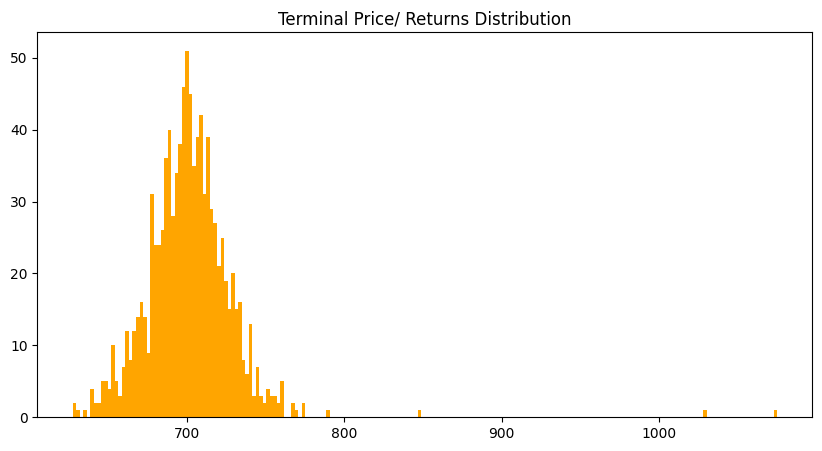

In [27]:
plt.figure(figsize=(10,5))
plt.hist(mc.final_prices, bins=200, color="orange")
#plt.hist((np.array(mc.final_prices) - SPOT_PRICE)/SPOT_PRICE * 100, bins=200, color="orange")
plt.title('Terminal Price/ Returns Distribution')
plt.show()

Text(0.5, 1.0, 'MC Convergence')

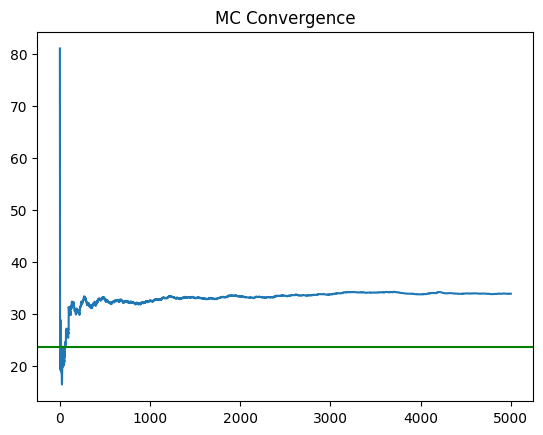

In [200]:
plt.plot(mc.payoffs_hist, label="mc payoffs")
plt.axhline((c['bid']+c['ask'])/2, color="green", label="market mid price")
plt.title('MC Convergence')

(1000, 367)
0.9859428405273024


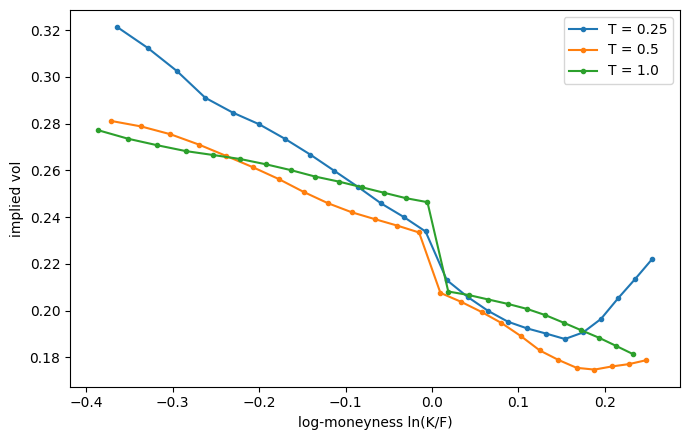

In [231]:
def mc_smile(S_paths, S0, r, T, step_idx, strikes):
    """IV for each strike at one maturity. Uses OTM options (puts below the
    forward, calls above) because they have much lower MC noise."""
    ST = S_paths[:, step_idx]
    disc = np.exp(-r * T)
    F = S0 * np.exp(r * T)
    ivs = []
    for K in strikes:
        call = K >= F
        payoff = np.maximum(ST - K, 0) if call else np.maximum(K - ST, 0)
        ivs.append(implied_vol(disc * payoff.mean(), S0, K, T, r, call))
    return np.array(ivs)


# ---- 1. IV smile at three maturities
# this will return a 2d array of price paths
T, r, dt = 1.0, 0.03, 1/365
SPOT_PRICE = 100.0
sigma = 0.20                      # sqrt(theta)

S = MonteCarloSim(HestonMertonGBM(initial_asset_price=SPOT_PRICE, mu=r,
                                  Lambda=0.5, mu_j=-0.10, sigma_j=0.15,
                                  kappa_v=2.0, theta=0.04, xi=0.3, rho=-0.7,
                                  initial_variance=sigma**2, dt=dt),
                  call_strike=SPOT_PRICE, n_options=1000,
                  rfr=r, tte=T, barrier=0).all

# sanity checks before trusting any smile
S = np.array(S)
print(S.shape)                                      # want (n_paths, 366)
print(S[:, -1].mean() / (SPOT_PRICE * np.exp(r*T))) # want ~1.000

strikes = SPOT_PRICE * np.linspace(0.7, 1.3, 25)
plt.figure(figsize=(7, 4.5))
for T_m in [0.25, 0.5, 1.0]:
    idx = int(round(T_m / dt))
    iv = mc_smile(S, SPOT_PRICE, r, T_m, idx, strikes)
    plt.plot(np.log(strikes / (SPOT_PRICE * np.exp(r*T_m))), iv,
             marker="o", ms=3, label=f"T = {T_m}")
plt.xlabel("log-moneyness ln(K/F)"); plt.ylabel("implied vol")
plt.title('IV smile/skew')
plt.legend(); plt.tight_layout(); plt.show()


1y ATM call: MC price 10.555, implied vol 22.951%

Bates, daily hedge         mean  -0.002  std  3.232 ( 30.6% of premium)  CVaR5% -10.397
Bates, weekly hedge        mean  -0.010  std  3.391 ( 32.1% of premium)  CVaR5% -10.733
Bates, monthly hedge       mean   0.000  std  3.820 ( 36.2% of premium)  CVaR5% -11.444
GBM baseline, daily        mean  -0.000  std  0.503 (  4.8% of premium)  CVaR5%  -1.155


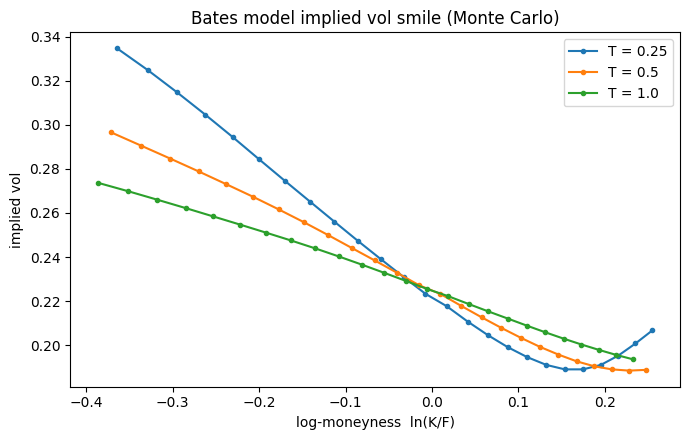

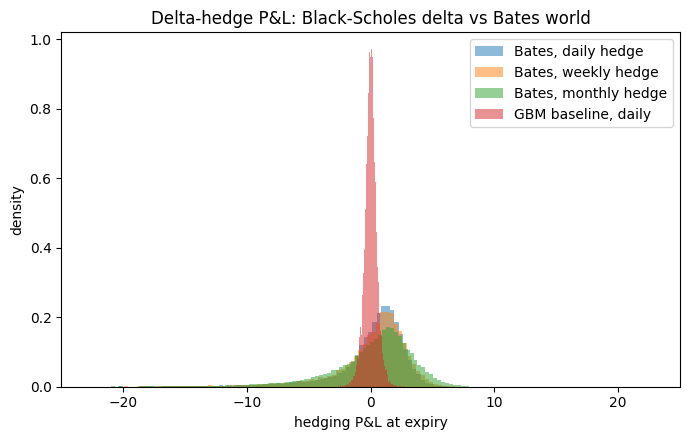

In [28]:
"""
IV smile + delta-hedging experiment for a Heston + Merton (Bates) Monte Carlo.

Swap `simulate_bates` for your own simulator if you like: all you need is a
function that returns a (n_paths, n_steps+1) array of risk-neutral prices.
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

# ---------------------------------------------------------------- simulator
def simulate_bates(S0, v0, r, kappa, theta, xi, rho, lam, muJ, sigJ,
                   T, n_steps, n_paths, seed=0):
    """Risk-neutral Heston + Merton jumps. Full-truncation Euler for variance."""
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    k = np.exp(muJ + 0.5 * sigJ**2) - 1          # jump compensator E[e^J]-1
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    v = np.full(n_paths, v0)
    for t in range(n_steps):
        z1 = rng.standard_normal(n_paths)
        z2 = rho * z1 + np.sqrt(1 - rho**2) * rng.standard_normal(n_paths)
        vp = np.maximum(v, 0.0)
        sv = np.sqrt(vp)
        N = rng.poisson(lam * dt, n_paths)
        J = muJ * N + sigJ * np.sqrt(N) * rng.standard_normal(n_paths)
        S[:, t + 1] = S[:, t] * np.exp((r - lam * k - 0.5 * vp) * dt
                                       + sv * np.sqrt(dt) * z1 + J)
        v = v + kappa * (theta - vp) * dt + xi * sv * np.sqrt(dt) * z2
    return S

# ------------------------------------------------------------ Black-Scholes
def bs_price(S, K, T, r, sig, call=True):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    d2 = d1 - sig * np.sqrt(T)
    if call:
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

def bs_delta(S, K, tau, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * tau) / (sig * np.sqrt(tau))
    return norm.cdf(d1)

def implied_vol(price, S, K, T, r, call=True):
    intrinsic = max((S - K * np.exp(-r * T)) if call else (K * np.exp(-r * T) - S), 0)
    if price <= intrinsic + 1e-10:
        return np.nan
    try:
        return brentq(lambda s: bs_price(S, K, T, r, s, call) - price, 1e-4, 5.0)
    except ValueError:
        return np.nan

# ------------------------------------------------------------- IV smile
def mc_smile(S_paths, S0, r, T, step_idx, strikes):
    """IV for each strike at one maturity. Uses OTM options (puts below the
    forward, calls above) because they have much lower MC noise."""
    ST = S_paths[:, step_idx]
    disc = np.exp(-r * T)
    F = S0 * np.exp(r * T)
    ivs = []
    for K in strikes:
        call = K >= F
        payoff = np.maximum(ST - K, 0) if call else np.maximum(K - ST, 0)
        ivs.append(implied_vol(disc * payoff.mean(), S0, K, T, r, call))
    return np.array(ivs)

# ---------------------------------------------------------- delta hedging
def delta_hedge_pnl(S, K, T, r, sigma, premium, every=1):
    """P&L at expiry of: sell a call at `premium`, delta-hedge with
    Black-Scholes delta (vol = sigma), rebalancing every `every` steps."""
    n = S.shape[1] - 1
    dt = T / n
    delta = bs_delta(S[:, 0], K, T, r, sigma)
    cash = premium - delta * S[:, 0]
    for i in range(1, n + 1):
        cash *= np.exp(r * dt)
        if i % every == 0 and i < n:
            new = bs_delta(S[:, i], K, T - i * dt, r, sigma)
            cash -= (new - delta) * S[:, i]
            delta = new
    return cash + delta * S[:, -1] - np.maximum(S[:, -1] - K, 0)

def summarize(name, pnl, premium):
    cvar = pnl[pnl <= np.quantile(pnl, 0.05)].mean()
    print(f"{name:<26} mean {pnl.mean():7.3f}  std {pnl.std():6.3f} "
          f"({100 * pnl.std() / premium:5.1f}% of premium)  CVaR5% {cvar:7.3f}")

# -------------------------------------------------------------------- main
if __name__ == "__main__":
    P = dict(S0=100.0, v0=0.04, r=0.03, kappa=2.0, theta=0.04, xi=0.3,
             rho=-0.7, lam=0.5, muJ=-0.10, sigJ=0.15)
    T, n_steps = 1.0, 252
    S0, r = P["S0"], P["r"]

    # ---- 1. IV smile at three maturities
    S = simulate_bates(**P, T=T, n_steps=n_steps, n_paths=50_000, seed=1)
    strikes = np.linspace(70, 130, 25)
    plt.figure(figsize=(7, 4.5))
    for T_m, idx in [(0.25, 63), (0.5, 126), (1.0, 252)]:
        iv = mc_smile(S, S0, r, T_m, idx, strikes)
        plt.plot(np.log(strikes / (S0 * np.exp(r * T_m))), iv, marker="o",
                 ms=3, label=f"T = {T_m}")
    plt.xlabel("log-moneyness  ln(K/F)")
    plt.ylabel("implied vol")
    plt.title("Bates model implied vol smile (Monte Carlo)")
    plt.legend()
    plt.tight_layout()
    plt.savefig("iv_smile.png", dpi=150)

    # ---- 2. Delta hedging a 1y ATM call
    K = 100.0
    prem = np.exp(-r * T) * np.maximum(S[:, -1] - K, 0).mean()
    iv_atm = implied_vol(prem, S0, K, T, r, True)
    print(f"\n1y ATM call: MC price {prem:.3f}, implied vol {iv_atm:.3%}\n")

    S_h = simulate_bates(**P, T=T, n_steps=n_steps, n_paths=20_000, seed=2)
    res = {
        "Bates, daily hedge": delta_hedge_pnl(S_h, K, T, r, iv_atm, prem, 1),
        "Bates, weekly hedge": delta_hedge_pnl(S_h, K, T, r, iv_atm, prem, 5),
        "Bates, monthly hedge": delta_hedge_pnl(S_h, K, T, r, iv_atm, prem, 21),
    }
    # baseline: pure GBM at the same implied vol (BS world)
    gbm = dict(P, v0=iv_atm**2, theta=iv_atm**2, xi=1e-8, lam=0.0, kappa=1.0)
    S_g = simulate_bates(**gbm, T=T, n_steps=n_steps, n_paths=20_000, seed=3)
    prem_g = bs_price(S0, K, T, r, iv_atm, True)
    res["GBM baseline, daily"] = delta_hedge_pnl(S_g, K, T, r, iv_atm, prem_g, 1)
    for name, pnl in res.items():
        summarize(name, pnl, prem if "Bates" in name else prem_g)

    plt.figure(figsize=(7, 4.5))
    for name, pnl in res.items():
        plt.hist(pnl, bins=120, alpha=0.5, density=True, label=name)
    plt.xlim(-25, 25)
    plt.xlabel("hedging P&L at expiry")
    plt.ylabel("density")
    plt.title("Delta-hedge P&L: Black-Scholes delta vs Bates world")
    plt.legend()
    plt.tight_layout()
    plt.savefig("hedge_pnl.png", dpi=150)
    plt.show()
